# EQUINE Image Classification Example

This notebook walks through a simple application of a Neural Network trained on a vision task -- predicting a clothing article in the FashionMNIST dataset -- as applied to image data from that and from regular MNIST, a handwritten digit dataset. In this, we load the datasets, train a model, wrap the model with two EQUINE architectures, and demonstrate out-of-distribution performance. 

This notebook requires some extra dependencies to run. You can uncomment the below cell to install them into your local environment.

In [1]:
#!pip install matplotlib, torchvision, scipy

In [2]:
import equine as eq

import torch
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
import scipy
from torchvision import datasets
from torchvision.transforms import ToTensor
from torchmetrics.classification import MulticlassAccuracy 
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

In [3]:
# Seed the random number generator that model initialization and training use,
# so that re-running this notebook on the same platform and library versions
# reproduces the outputs below
_ = torch.manual_seed(52)

### 1. Load MNIST and FashionMNIST Datasets

In [4]:
training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(),
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)

X_train = training_data.data
Y_train = training_data.targets
X_train = X_train.type(torch.float32)
X_train = torch.unsqueeze(X_train, 1)

X_test = test_data.data
Y_test = test_data.targets
X_test = X_test.type(torch.float32)
X_test = torch.unsqueeze(X_test, 1)

trainloader = DataLoader(training_data,batch_size=64,shuffle=True, drop_last=True)
testloader = DataLoader(test_data,batch_size=64,shuffle=True, drop_last=True)

ood_data = datasets.MNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
)
X_ood = ood_data.data
X_ood = X_ood.type(torch.float32)
X_ood = torch.unsqueeze(X_ood, 1)

oodloader = DataLoader(ood_data,batch_size=64,shuffle=True, drop_last=True)

### 2. Create Embedding Model

We define a simple CNN using the LeNet architecture and our embedding model, which can freeze chosen layers so that they are not updated during training. The class is registered with `@eq.embedding_architecture`, because `model.save()` stores an embedding model as the name of a registered architecture plus its plain-valued constructor arguments and weights (rather than as executable code), and refuses a class that is not registered. So its constructor takes the names of the layers to freeze, and the learned weights are copied in after construction.

In [5]:
class LeNet(torch.nn.Module):

    def __init__(self):
        super(LeNet, self).__init__()
        self.conv1 = torch.nn.Conv2d(1, 6, 5, padding=2)
        self.conv2 = torch.nn.Conv2d(6, 16, 5)
        self.fc1   = torch.nn.Linear(16*5*5, 120)
        self.fc2   = torch.nn.Linear(120, 84)
        self.fc3   = torch.nn.Linear(84, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), (2, 2))
        x = F.max_pool2d(F.relu(self.conv2(x)), (2, 2))
        x = x.view(-1, self.num_flat_features(x))
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

    def num_flat_features(self, x):
        size = x.size()[1:]
        return torch.prod(torch.tensor(size))

@eq.embedding_architecture("examples.lenet_embedding")
class EmbeddingModel(LeNet):

    # the weights of the layers named in `frozen` (e.g. "conv1") are
    # not updated during training
    def __init__(self, frozen=()):
        super(EmbeddingModel, self).__init__()
        for name in frozen:
            self.get_submodule(name).weight.requires_grad = False


def pretrained_embedding(source, frozen):
    """A new EmbeddingModel whose `frozen` layers have the weights learned by `source`."""
    embedding = EmbeddingModel(frozen=frozen)
    with torch.no_grad():
        for name in frozen:
            embedding.get_submodule(name).weight.copy_(source.get_submodule(name).weight)
    return embedding

We train the model for 30 epochs using SGD with two scheduled drops in learning rate.

In [6]:
model_orig = EmbeddingModel()
loss_fn = torch.nn.CrossEntropyLoss()
opt = torch.optim.SGD(
        model_orig.parameters(),
        lr=0.01,
        momentum=0.9,
        weight_decay=0.0001,
    )
scheduler = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[20,25], gamma=0.1)

train_accuracy = MulticlassAccuracy(10)
for epoch in range(30):
    epoch_loss = 0.0
    for i, (xs, labels) in enumerate(trainloader):
        opt.zero_grad()
        yhats = model_orig(xs)
        loss = loss_fn(yhats, labels)
        batch_acc = train_accuracy(yhats, labels)
        loss.backward()
        opt.step()
        epoch_loss += loss.item()
    #print(epoch_loss)
    total_train_accuracy = train_accuracy.compute()
    scheduler.step()

    print("Training acc for epoch {}: {:.3f}".format(epoch, total_train_accuracy))

Training acc for epoch 0: 0.704
Training acc for epoch 1: 0.775
Training acc for epoch 2: 0.807
Training acc for epoch 3: 0.826
Training acc for epoch 4: 0.839
Training acc for epoch 5: 0.848
Training acc for epoch 6: 0.856
Training acc for epoch 7: 0.862
Training acc for epoch 8: 0.867
Training acc for epoch 9: 0.872
Training acc for epoch 10: 0.876
Training acc for epoch 11: 0.880
Training acc for epoch 12: 0.883
Training acc for epoch 13: 0.886
Training acc for epoch 14: 0.888
Training acc for epoch 15: 0.891
Training acc for epoch 16: 0.893
Training acc for epoch 17: 0.896
Training acc for epoch 18: 0.898
Training acc for epoch 19: 0.900
Training acc for epoch 20: 0.902
Training acc for epoch 21: 0.905
Training acc for epoch 22: 0.907
Training acc for epoch 23: 0.910
Training acc for epoch 24: 0.912
Training acc for epoch 25: 0.914
Training acc for epoch 26: 0.915
Training acc for epoch 27: 0.917
Training acc for epoch 28: 0.919
Training acc for epoch 29: 0.920


To evaluate the model, we first consider its accuracy on the test dataset and then look at how well its predictive probabilities allow us to separate in-distribution data from out-of-distribution (OOD) data.  To do this, we compute the entropy of the predictive probability distribution.  Ideally, the model will produce predictions with low entropy for in distribution data and predictions with high entropy for out of distribution data.

Model accuracy on test set: 0.911


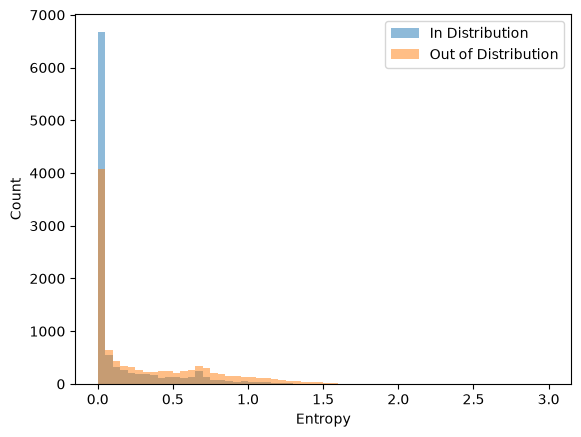

AUROC for detecting out of distribution examples: 0.687


In [7]:
model_orig.eval()

oods_in_dist = []
predictions = []
true_labels = []
for i, (xs, labels) in enumerate(testloader):
    y_pred = model_orig(xs).detach().numpy()
    oods = np.sum(scipy.special.entr(scipy.special.softmax(y_pred, axis=1)), axis=1)
    oods_in_dist.extend(list(oods))
    predictions.extend(list(np.argmax(y_pred, axis=1)))
    true_labels.extend(list(labels))
predictions = np.array(predictions)
true_labels = np.array(true_labels)
print('Model accuracy on test set: {:.3f}'.format(np.mean(predictions == true_labels)))
    
oods_out_dist = []
for i, (xs, labels) in enumerate(oodloader):
    y_pred = model_orig(xs).detach().numpy()
    oods = np.sum(scipy.special.entr(scipy.special.softmax(y_pred, axis=1)), axis=1)
    oods_out_dist.extend(list(oods))
    
plt.hist(oods_in_dist,bins=np.linspace(0,3,61),alpha=0.5, label='In Distribution')
plt.hist(oods_out_dist,bins=np.linspace(0,3,61),alpha=0.5, label='Out of Distribution')
plt.xlabel('Entropy')
plt.ylabel('Count')
plt.legend()
plt.show()
roc = roc_auc_score(np.hstack((np.ones_like(oods_out_dist),np.zeros_like(oods_in_dist))),
              oods_out_dist+oods_in_dist)
print('AUROC for detecting out of distribution examples: {:.3f}'.format(roc))

While the original model performs well on the in-distribution test data, its predictive probabilities do not allow us to discriminate between in-distribution and out-of-distribution data.  For example, the model confidently predicts below that the digit 7 belongs to one of the Fashion MNIST labels.

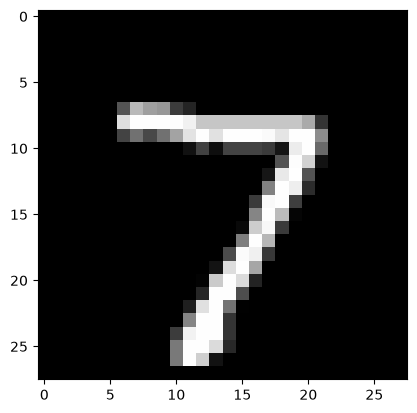

Predictive probabilities:
[[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]]


In [8]:
plt.imshow(X_ood[0:1].reshape(28,28), cmap="gray")
plt.show()
print('Predictive probabilities:')
print(scipy.special.softmax(model_orig(X_ood[0:1]).detach().numpy(), axis=1))

Seeing the limitations of the original model, we will now freeze all but the output layer and wrap the model with two different equine models.

### 3. Wrap embedding model with EquineGP

We first create a new EmbeddingModel whose first four layers are frozen at the weights that we learned above.  We then wrap that EmbeddingModel in EquineGP.  The resulting model has an extra Gaussian Process "layer" on top of the original model.

In [9]:
model_GP = eq.EquineGP(pretrained_embedding(model_orig, ["conv1", "conv2", "fc1", "fc2"]), 
                      emb_out_dim=10, num_classes = 10,
                      label_names=["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"] )

We now train for a few more epochs to fine tune the last layer of the original model and learn the parameters in the Gaussian Process layer.

In [10]:
loss_fn = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
        model_GP.model.parameters(),
        lr=0.001,
        momentum=0.9,
        weight_decay=0.0,
    )
res_GP = model_GP.train_model(TensorDataset(X_train, Y_train), loss_fn, optimizer, 5, vis_support=True)

100%|██████████| 5/5 [00:31<00:00,  6.28s/it]


We now compute the test accuracy and out of distribution results to compare with the original model.

Model accuracy on test set: 0.898


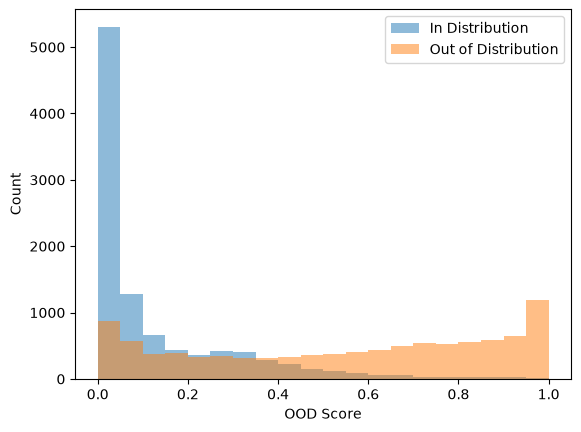

AUROC for detecting out of distribution examples: 0.865


In [11]:
oods_in_dist = []
predictions = []
true_labels = []
for i, (xs, labels) in enumerate(testloader):
    y_pred = model_GP.predict(xs)
    classes = y_pred.classes.detach().numpy()
    oods = y_pred.ood_scores.detach().numpy()
    oods_in_dist.extend(list(oods))
    predictions.extend(list(np.argmax(classes, axis=1)))
    true_labels.extend(list(labels))
predictions = np.array(predictions)
true_labels = np.array(true_labels)
print('Model accuracy on test set: {:.3f}'.format(np.mean(predictions == true_labels)))
    
oods_out_dist = []
for i, (xs, labels) in enumerate(oodloader):
    y_pred = model_GP.predict(xs)
    oods = y_pred.ood_scores.detach().numpy()
    oods_out_dist.extend(list(oods))
    
plt.hist(oods_in_dist,bins=np.linspace(0,1,21),alpha=0.5, label='In Distribution')
plt.hist(oods_out_dist,bins=np.linspace(0,1,21),alpha=0.5, label='Out of Distribution')
plt.xlabel('OOD Score')
plt.ylabel('Count')
plt.legend()
plt.show()
roc = roc_auc_score(np.hstack((np.ones_like(oods_out_dist),np.zeros_like(oods_in_dist))),
              oods_out_dist+oods_in_dist)
print('AUROC for detecting out of distribution examples: {:.3f}'.format(roc))

The EquineGP model clearly does a much better job of separating the in distribution and out of distribution data.  Returning to the digit 7 below, the original model put all of its probability on one class. How the EquineGP model scores a single example depends on training: in the run saved here, it is also confident about this digit and gives it a low out of distribution score, while other training runs (with other seeds, platforms or library versions) usually give it lower confidence and a higher score. The AUROC above, computed over all of the test and out of distribution data, is the better measure of how well the model separates the two.  The EquineGP out of distribution score is the entropy of the probabilities scaled to between 0 and 1 and is computed internally.

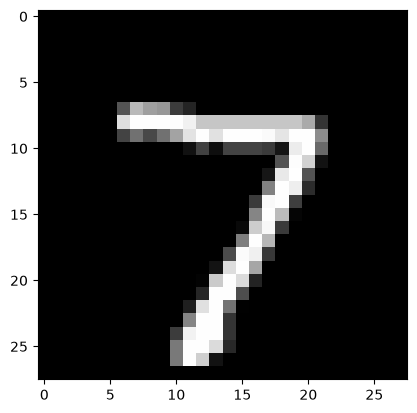

Predictive probabilities: [0.00666384 0.0025159  0.00422171 0.00238694 0.00299923 0.9410593
 0.00504201 0.00810457 0.01574158 0.01126484]
Out of distribution score: [0.14858101]


In [12]:
plt.imshow(X_ood[0:1].reshape(28,28), cmap="gray")
plt.show()
print('Predictive probabilities: {}'.format(scipy.special.softmax(model_GP(X_ood[0:1]).detach().numpy(), axis=1)[0]))
print('Out of distribution score: {}'.format(model_GP.predict(X_ood[0:1]).ood_scores.detach().numpy()))

### 4. Wrap embedding model with EquineProtonet

Our second wrapper replaces the softmax output of the original model with a protonet.

In [13]:
model_Proto = eq.equine_protonet.EquineProtonet(pretrained_embedding(model_orig, ["conv1", "conv2", "fc1", "fc2"]), 
                        emb_out_dim=10, cov_type=eq.CovType.DIAGONAL, use_temperature=True, relative_mahal=False,
                        label_names=["T-shirt/top","Trouser","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"] )

To adapt to the new output, we fine tune the last layer.

In [14]:
res_Proto = model_Proto.train_model(TensorDataset(X_train, Y_train), num_episodes=3000, 
                        support_size=10, 
                        way=10, 
                        episode_size=1000)

100%|██████████| 3000/3000 [04:14<00:00, 11.79it/s]


We now compute the test accuracy and out of distribution results to compare with the original model.

Model accuracy on test set: 0.882


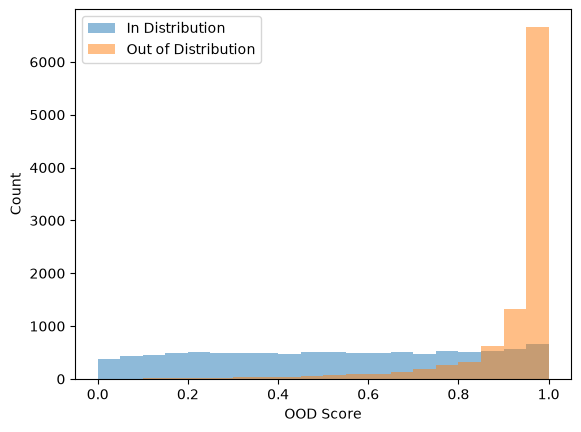

AUROC for detecting out of distribution examples: 0.914


In [15]:
oods_out_dist = model_Proto.predict(X_ood).ood_scores
oods_out_dist = oods_out_dist.detach().numpy()
oods_in_dist = model_Proto.predict(X_test).ood_scores
oods_in_dist = oods_in_dist.detach().numpy()

predictions = np.argmax(model_Proto.predict(X_test).classes.detach().numpy(), axis=1)
print('Model accuracy on test set: {0:.3f}'.format(np.mean(predictions == Y_test.detach().numpy())))

plt.hist(oods_in_dist,bins=np.linspace(0,1,21),alpha=0.5, label='In Distribution')
plt.hist(oods_out_dist,bins=np.linspace(0,1,21),alpha=0.5, label='Out of Distribution')
plt.xlabel('OOD Score')
plt.ylabel('Count')
plt.legend()
plt.show()

roc = roc_auc_score(np.hstack((np.ones_like(oods_out_dist),np.zeros_like(oods_in_dist))),
              list(oods_out_dist)+list(oods_in_dist))
print('AUROC for detecting out of distribution examples: {0:.3f}'.format(roc))

The protonet also does a good job of separating in distribution and out of distribution data, though its accuracy is lower than the original model for the Gaussian Process model.  The OOD score produced by the protonet is based on the distance to a representation of the closest class, rather than on the entropy of predictive probabilities.  One minus the OOD score of a particular example can be interpreted as the probability of observing an in distribution example that is further from its closest class representation than the example point.  As a result, the ood scores for the in distribution data roughly follow a uniform distribution.

Below, we see that the out out of distribution example receives a high OOD score.

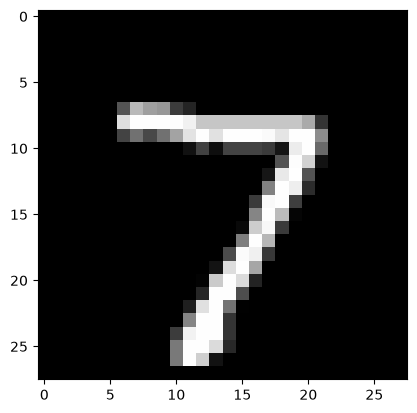

Out of distribution score:
[0.9439644]


In [16]:
plt.imshow(X_ood[0:1].reshape(28,28), cmap="gray")
plt.show()
print('Out of distribution score:')
print(model_Proto.predict(X_ood[0:1]).ood_scores.detach().numpy())

In [17]:
# Save out the GP and Protonet models for visualization in the web-app
model_GP.save("vis_FashionMNIST_GP.eq")
model_Proto.save("vis_FashionMNIST_protonet.eq")

In [18]:
# Save out some randomized datasets to load into the web-app
idxs = torch.randperm(X_test.size(0))[:50]
some_fashion_x = X_test[idxs]
some_fashion_y = Y_test[idxs]
torch.save(TensorDataset(some_fashion_x, some_fashion_y), "some_fashion_mnist_test_data.pt")

idxs = torch.randperm(X_ood.size(0))[:50]
some_digits_x = X_ood[idxs]
some_digits_y = X_ood[idxs]
torch.save(TensorDataset(some_digits_x, some_digits_y), "some_digits_mnist_test_data.pt")
